<a href="https://colab.research.google.com/github/samuelfueter/IMAPP-Quantum_Computing/blob/main/Jupyter%20Notebooks/QCTP_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install qiskit qiskit-aer

In [ ]:
import numpy as np
from numpy import linalg as LA
from qiskit import quantum_info as qi
from qiskit.visualization import array_to_latex, plot_bloch_multivector

#### limit the precision in printing (from NumPy only)

In [ ]:
np.set_printoptions(precision=4)
print(np.array([1.23456789]))

[1.2346]


#### create a row vector

In [ ]:
v = np.array([1., 1., 0.])
print(v)

[1. 1. 0.]


#### create a column vector

In [ ]:
v = np.array([[1.], [1.], [0.]])
print(v)

[[1.]
 [1.]
 [0.]]


#### add two vectors

In [ ]:
v1 = np.array([1., 1., 0.])
v2 = np.array([1., 1., 1.])
vs = v1 + v2
print(vs)

[2. 2. 1.]


#### multiply a vector with a complex constant

In [ ]:
c = complex(0.5, 0.4)
print(c)

(0.5+0.4j)


In [ ]:
print(c*v1)

[0.5+0.4j 0.5+0.4j 0. +0.j ]


#### the (internal) scalar product of two vectors

In [ ]:
sp = LA.vecdot(v1, v2)
print(sp)

2.0


#### a "ket" $\lvert v \rangle$ vector

In [ ]:
vket = np.array([[1.],[1j]])
print(vket)

[[1.+0.j]
 [0.+1.j]]


#### a "bra" $\langle v \rvert$ vector

In [ ]:
vbra = vket.T.conj()
print(vbra)

[[1.-0.j 0.-1.j]]


#### the (external) scalar product between a "bra" and a "ket"

In [ ]:
print(vbra.dot(vket))

[[2.+0.j]]


#### a (ket) state vector with Qiskit

In [ ]:
sv = qi.Statevector(np.array([1., 0.]))
print(sv)

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))


#### pretty printing

In [ ]:
array_to_latex(sv)

<IPython.core.display.Latex object>

#### to how many qubits correspond this state vector?

In [ ]:
sv.num_qubits

1

#### plot the state vector on the Bloch sphere

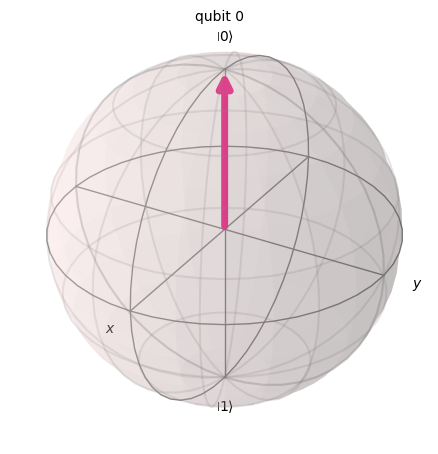

In [ ]:
plot_bloch_multivector(sv)

#### a unitary operator with Qiskit

In [ ]:
op = qi.Operator(np.array([[0., 1.], [1., 0.]]))
print(op)

Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


In [ ]:
op.is_unitary()

True

#### a unitary operator with random elements

In [ ]:
U = qi.random_unitary(2, seed = 123456)
print(U)

Operator([[ 0.27056634+0.52104653j, -0.4594307 +0.66650417j],
          [ 0.6111021 +0.53090356j,  0.13210743-0.57205179j]],
         input_dims=(2,), output_dims=(2,))


#### the adjoint operator $U^{\dagger}$

In [ ]:
Udag = U.adjoint()
print(Udag)

Operator([[ 0.27056634-0.52104653j,  0.6111021 -0.53090356j],
          [-0.4594307 -0.66650417j,  0.13210743+0.57205179j]],
         input_dims=(2,), output_dims=(2,))


#### the composition $U^{\dagger} U$

In [ ]:
# Udag U
print(U.compose(Udag))

Operator([[1.00000000e+00+0.00000000e+00j, 1.38777878e-16-1.11022302e-16j],
          [1.38777878e-16+1.11022302e-16j, 1.00000000e+00+0.00000000e+00j]],
         input_dims=(2,), output_dims=(2,))


#### the composition $U U^{\dagger}$

In [ ]:
# U Udag
print(Udag.compose(U))

Operator([[ 1.00000000e+00+0.j, -3.46944695e-16+0.j],
          [-3.46944695e-16+0.j,  1.00000000e+00+0.j]],
         input_dims=(2,), output_dims=(2,))


#### pretty printing

In [ ]:
array_to_latex(U, precision=4)

<IPython.core.display.Latex object>

#### special unitary operators: the $X$ Pauli operator

In [ ]:
X = qi.Operator(qi.Pauli('X'))
print(X)

Operator([[0.+0.j, 1.+0.j],
          [1.+0.j, 0.+0.j]],
         input_dims=(2,), output_dims=(2,))


#### the $Z$ Pauli operator

In [ ]:
Z = qi.Operator(qi.Pauli('Z'))
print(Z)

Operator([[ 1.+0.j,  0.+0.j],
          [ 0.+0.j, -1.+0.j]],
         input_dims=(2,), output_dims=(2,))


#### the tensor product of two operators $X \otimes Z$

In [ ]:
print(X.tensor(Z))

Operator([[ 0.+0.j,  0.+0.j,  1.+0.j,  0.+0.j],
          [ 0.+0.j, -0.+0.j,  0.+0.j, -1.+0.j],
          [ 1.+0.j,  0.+0.j,  0.+0.j,  0.+0.j],
          [ 0.+0.j, -1.+0.j,  0.+0.j, -0.+0.j]],
         input_dims=(2, 2), output_dims=(2, 2))


#### the evolution of a state vector by a unitary operator

In [ ]:
sv0 = qi.Statevector(np.array([1., 0.]))
sv1 = sv0.evolve(X)
print(sv1)

Statevector([0.+0.j, 1.+0.j],
            dims=(2,))
